# 08 — Specialist Decoupled Dual-Head (`PM3-Decoupled`): Anti-Overfit, Boundary-Focused Diagnosis, High-Epoch Complication Stability, & Selective Gated MIL

Notebook ini menguji perbaikan arsitektural dan strategi pelatihan yang dirancang khusus untuk menjawab **4 kondisi empiris utama** secara terpisah pada masing-masing kepala (`Diag-Specialist` vs `Comp-Specialist`) dengan protokol evaluasi *strict zero-leakage* 5-Fold Stratified CV yang identik (`N=578`, `seed=1`, `clean_28`):

1. **Menekan Overfitting secara Agresif:** Kompresi dimensi laten (`128 -> 64`), *Dropout* di dalam `ResidualFiLM` (`0,30`) & sebelum *classifier head* (`0,30`), *input Gaussian jitter* tabular (`0,08`) & visual (`0,05`), *random bag view dropout* (`p=0,35` bila $K_i \ge 3$), *weight decay* kuat (`1e-2`–`3e-2`), *binary label smoothing*, *CosineAnnealingLR* khusus pasca-*warmup*, *Model EMA* (`decay=0,98`), dan seleksi *checkpoint* berpenjaga *loss* (*loss-guarded selection*).
2. **Memperbaiki Deteksi `No Appendicitis` vs `Uncomplicated`:** `Diag-Specialist` memakai *Boundary-Focused Asymmetric Focal BCE* ($\gamma=1,5$, bobot kasus mudah `Complicated` diturunkan ke `0,50` sedangkan zona batas `Uncomplicated` `1,15`) dan 5 konsep diagnostik spesifik.
3. **Menjaga Stabilitas `Complicated` di Epoch Lanjut:** `Comp-Specialist` dilatih independen khusus pasien apendisitis (`286 Unc vs 96 Comp`) dengan *LR* lebih rendah (`backbone=8e-6`, `attn=1,5e-4`, `head=2,0e-4`), `label_smoothing=0,08`, *EMA*, dan audit stabilitas `Ep 5 -> Ep 10 -> Ep 15 -> Ep 20 -> Ep 25 -> Ep 30`.
4. **Mengatasi `agg_comp` yang Terlalu Datar (~MIL-Mean):** Mengganti agregator `agg_comp` dengan **Clinical-Conditioned Gated Attention MIL (Ilse et al., 2018)** ber-temperatur tajam (`tau=0,45`), tanpa *mean-residual bypass*, *modality dropout* klinis lebih kuat (`0,35`), dan *gentle anti-uniform entropy regularization* (`0,03 * H_norm` pada bag multiview), disertai **uji faithfulness** (`GatedMIL` vs `Uniform Mean` pada bobot terlatih yang sama).


In [1]:
import copy, gc, json, math, random, sys, time
from dataclasses import asdict, dataclass
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from scipy.stats import binomtest
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    recall_score,
    roc_auc_score,
)

candidates = [Path.cwd(), *Path.cwd().parents]
PM3_DIR = next(
    (p if (p / "pm3_data.py").is_file() else p / "Proposed Model 3")
    for p in candidates
    if (p / "pm3_data.py").is_file() or (p / "Proposed Model 3" / "pm3_data.py").is_file()
)
ROOT_DIR = PM3_DIR.parent
if str(PM3_DIR) not in sys.path:
    sys.path.insert(0, str(PM3_DIR))

from pm3_data import (
    CLASS_NAMES,
    CONCEPTS_PM3,
    ClinicalPipeline,
    PM3PatientBagDataset,
    USConfig,
    build_image_cache,
    collate_patients,
    encode_pm3_concepts,
    images_by_patient,
    load_cohort,
    make_stratified_folds,
)
from pm3_model import CLASS_IDS, EfficientNetB0Encoder, ModelConfig
from pm3_train import (
    bootstrap_ci,
    calibrate_thresholds_nested_oof,
    compute_metrics,
    save_json,
    set_seed,
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True
    print("GPU:", torch.cuda.get_device_name(0), "| VRAM free/total (GiB):",
          [round(x / 1024**3, 2) for x in torch.cuda.mem_get_info()])
else:
    print("Device:", DEVICE)

RUNS_DIR = PM3_DIR / "runs"
OUT_DIR = RUNS_DIR / "08_decoupled_dualhead"
OUT_DIR.mkdir(parents=True, exist_ok=True)

SKIP_IF_DONE = True

cohort = load_cohort(ROOT_DIR / "app_data_filtered.csv")
manifest = pd.read_csv(ROOT_DIR / "image_manifest_filtered.csv")
manifest["image_id"] = manifest["image_id"].astype(str)
manifest = manifest.loc[manifest["US_Number"].isin(cohort.index)].copy().reset_index(drop=True)
folds = make_stratified_folds(cohort, seed=1, n_splits=5)
bags_all = images_by_patient(manifest, bag_mode="all")
cache = build_image_cache(manifest, ROOT_DIR / "US_Pictures_clean", USConfig(), PM3_DIR / "cache")

print(f"Cohort: {len(cohort)} pasien | Folds: {len(folds)} | OUT_DIR: {OUT_DIR}")


GPU: NVIDIA GeForce RTX 3060 Laptop GPU | VRAM free/total (GiB): [5.0, 6.0]
Preprocessing/cache PM3: 250/1741
Preprocessing/cache PM3: 500/1741
Preprocessing/cache PM3: 750/1741
Preprocessing/cache PM3: 1000/1741
Preprocessing/cache PM3: 1250/1741
Preprocessing/cache PM3: 1500/1741
Cohort: 578 pasien | Folds: 5 | OUT_DIR: d:\Kuliah\Magister\Semester 1\Topik Dalam Pengolahan Citra Digital\Multimodal MIL-Attention based Hierarchical Classification Regensburg Pediatric Dataset\Proposed Model 3\runs\08_decoupled_dualhead


In [2]:
# ==============================================================================
# Cell 2: Compact Anti-Overfit Modules, Gated MIL Comp, EMA, & Specialist Engine
# ==============================================================================
DIAG_CONCEPT_IDX = [0, 1, 2, 3, 5]  # Appendix_on_US, Diameter, Target_Sign, Lymph_Nodes, Tissue_Reaction
COMP_CONCEPT_IDX = [1, 4, 5, 6, 7]  # Diameter, Wall_Layers, Tissue_Reaction, Free_Fluids, Severe_Signs


@dataclass
class SpecialistConfig:
    branch_name: str  # "diag" or "comp"
    concept_indices: Tuple[int, ...]
    epochs: int = 45
    warmup_freeze_epochs: int = 5
    patience: int = 15
    batch_size: int = 16
    seed: int = 1
    amp_fp16: bool = True
    # Compact dims + dropout
    img_dim: int = 64
    clin_hidden: int = 48
    clin_dim: int = 24
    vis_proj_dim: int = 24
    img_dropout: float = 0.45
    clin_dropout: float = 0.35
    film_dropout: float = 0.30
    head_dropout: float = 0.30
    attn_dropout: float = 0.15
    modality_dropout: float = 0.20
    # Regularization & jitter
    tab_jitter_std: float = 0.08
    vis_jitter_std: float = 0.05
    bag_view_drop_prob: float = 0.35
    label_smoothing: float = 0.06
    focal_gamma: float = 1.5
    entropy_reg_weight: float = 0.0
    # LRs & weight decay
    backbone_lr: float = 1.2e-5
    attention_lr: float = 2.0e-4
    head_lr: float = 3.0e-4
    backbone_wd: float = 2e-2
    attn_wd: float = 1e-2
    clin_wd: float = 3e-2
    head_wd: float = 2e-2
    scheduler_eta_min: float = 1e-6
    # Loss weights & temperatures
    w_concept: float = 0.35
    w_aux_img: float = 0.45
    attn_temperature: float = 0.60
    ema_decay: float = 0.98
    ema_start_epoch: int = 3
    loss_guard_penalty: float = 0.15


class RegularizedResidualFiLM(nn.Module):
    def __init__(self, cond_dim: int, feat_dim: int, hidden: int = 32, dropout: float = 0.30):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(cond_dim, hidden),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 2 * feat_dim),
        )
        nn.init.zeros_(self.net[-1].weight)
        nn.init.zeros_(self.net[-1].bias)

    def forward(self, feat: torch.Tensor, cond: torch.Tensor):
        params = self.net(cond)
        dg, beta = params.chunk(2, dim=-1)
        if feat.dim() == 2 and dg.dim() == 1:
            dg_b, beta_b = dg.unsqueeze(0), beta.unsqueeze(0)
        else:
            dg_b, beta_b = dg, beta
        return (1.0 + dg_b) * feat + beta_b, dg, beta


class CompactClinicalEncoder(nn.Module):
    def __init__(self, in_dim: int = 28, hidden: int = 48, out_dim: int = 24, dropout: float = 0.35):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden),
            nn.LayerNorm(hidden),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, out_dim),
            nn.LayerNorm(out_dim),
            nn.GELU(),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x.float())


class CompactCrossAttentionMIL(nn.Module):
    def __init__(self, dim: int = 64, num_heads: int = 4, temperature: float = 0.6,
                 dropout: float = 0.15, clinical_dim: int = 24):
        super().__init__()
        self.dim = dim
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.scale = math.sqrt(self.head_dim) * temperature

        self.q_proj = nn.Linear(dim, dim, bias=False)
        self.k_proj = nn.Linear(dim, dim, bias=False)
        self.v_proj = nn.Linear(dim, dim, bias=False)
        self.out_proj = nn.Linear(dim, dim)
        self.attn_drop = nn.Dropout(dropout)
        self.norm = nn.LayerNorm(dim)

        self.q_base = nn.Parameter(torch.randn(dim) * 0.04)
        self.q_clin = nn.Linear(clinical_dim, dim)
        nn.init.zeros_(self.q_clin.weight)
        nn.init.zeros_(self.q_clin.bias)

    def forward(self, h: torch.Tensor, e_clin: Optional[torch.Tensor] = None,
                uniform_override: bool = False):
        k_len = h.shape[0]
        if uniform_override:
            w = torch.full((k_len,), 1.0 / k_len, device=h.device, dtype=torch.float32)
            return h.float().mean(dim=0), w

        q_vec = self.q_base + (self.q_clin(e_clin) if e_clin is not None else 0.0)
        q = self.q_proj(q_vec).view(self.num_heads, 1, self.head_dim)
        k = self.k_proj(h).view(k_len, self.num_heads, self.head_dim).transpose(0, 1)
        v = self.v_proj(h).view(k_len, self.num_heads, self.head_dim).transpose(0, 1)
        scores = torch.matmul(q.float(), k.float().transpose(-2, -1)).squeeze(1) / self.scale
        w_heads = F.softmax(scores, dim=-1)
        w_drop = self.attn_drop(w_heads)
        ctx = torch.matmul(w_drop.unsqueeze(1), v.float()).squeeze(1).reshape(self.dim)
        w_mean = w_heads.mean(dim=0)
        res = (w_mean[:, None] * h.float()).sum(dim=0)
        return self.norm(self.out_proj(ctx) + res), w_mean


class ClinicalGatedAttentionMIL(nn.Module):
    # Clinical-conditioned Ilse et al. (2018) Gated Attention MIL without mean bypass.
    def __init__(self, dim: int = 64, hidden: int = 32, clinical_dim: int = 24,
                 temperature: float = 0.45, dropout: float = 0.15):
        super().__init__()
        self.temperature = temperature
        self.h_norm = nn.LayerNorm(dim)
        self.V = nn.Linear(dim, hidden, bias=True)
        self.U = nn.Linear(dim, hidden, bias=True)
        self.W_c = nn.Linear(clinical_dim, hidden, bias=False)
        self.w = nn.Linear(hidden, 1, bias=False)
        self.drop = nn.Dropout(dropout)
        self.out_norm = nn.LayerNorm(dim)
        for layer in (self.V, self.U, self.W_c, self.w):
            nn.init.xavier_uniform_(layer.weight)
            if layer.bias is not None:
                nn.init.zeros_(layer.bias)

    def forward(self, h: torch.Tensor, e_clin: Optional[torch.Tensor] = None,
                uniform_override: bool = False):
        k_len = h.shape[0]
        if uniform_override:
            weights = torch.full((k_len,), 1.0 / k_len, device=h.device, dtype=torch.float32)
            return self.out_norm(h.float().mean(dim=0)), weights

        hn = self.h_norm(h.float())
        clin_term = self.W_c(e_clin.float()).unsqueeze(0) if e_clin is not None else 0.0
        u = torch.tanh(self.V(hn) + clin_term)
        g = torch.sigmoid(self.U(hn))
        scores = self.w(self.drop(u * g)).squeeze(-1) / self.temperature
        weights = F.softmax(scores, dim=0)
        z = (weights[:, None] * h.float()).sum(dim=0)
        return self.out_norm(z), weights


class PM3SpecialistNet(nn.Module):
    def __init__(self, scfg: SpecialistConfig):
        super().__init__()
        self.scfg = scfg
        mcfg = ModelConfig(
            modality="multimodal",
            backbone_mode="stage7_only",
            aggregator="cross_attn",
            fusion_mode="film",
            task_mode="binary_diag" if scfg.branch_name == "diag" else "binary_sev",
            pretrained=True,
            image_microbatch=16,
            gradient_checkpointing=False,
        )
        self.encoder = EfficientNetB0Encoder(mcfg)
        self.img_proj = nn.Sequential(
            nn.Linear(self.encoder.out_channels, scfg.img_dim),
            nn.LayerNorm(scfg.img_dim),
            nn.GELU(),
            nn.Dropout(scfg.img_dropout),
        )
        if scfg.branch_name == "diag":
            self.agg = CompactCrossAttentionMIL(
                dim=scfg.img_dim, num_heads=4, temperature=scfg.attn_temperature,
                dropout=scfg.attn_dropout, clinical_dim=scfg.clin_dim,
            )
        else:
            self.agg = ClinicalGatedAttentionMIL(
                dim=scfg.img_dim, hidden=32, clinical_dim=scfg.clin_dim,
                temperature=scfg.attn_temperature, dropout=scfg.attn_dropout,
            )

        self.concept_head = nn.Linear(scfg.img_dim, len(scfg.concept_indices))
        self.aux_img_head = nn.Linear(scfg.img_dim, 1)

        self.clinical_mlp = CompactClinicalEncoder(28, scfg.clin_hidden, scfg.clin_dim, scfg.clin_dropout)
        self.clinical_skip = nn.Linear(28, 1)

        self.inst_film = RegularizedResidualFiLM(scfg.clin_dim, scfg.img_dim, hidden=32, dropout=scfg.film_dropout)
        self.bag_film = RegularizedResidualFiLM(scfg.clin_dim, scfg.img_dim, hidden=32, dropout=scfg.film_dropout)
        self.vis_anchor_proj = nn.Sequential(
            nn.Linear(scfg.img_dim, scfg.vis_proj_dim),
            nn.LayerNorm(scfg.vis_proj_dim),
            nn.GELU(),
        )
        self.head = nn.Sequential(
            nn.Dropout(scfg.head_dropout),
            nn.Linear(scfg.clin_dim + scfg.vis_proj_dim, 1),
        )

    def set_backbone_frozen(self, frozen: bool):
        self.encoder.set_backbone_frozen(frozen)

    def encode_images_chunked(self, images: torch.Tensor, pixel_masks: torch.Tensor, pad_to_microbatch: bool = False):
        step = 16
        n_orig = len(images)
        if pad_to_microbatch and (n_orig % step != 0):
            pad_n = step - (n_orig % step)
            images = torch.cat((images, images.new_zeros((pad_n, *images.shape[1:]))), dim=0)
            pixel_masks = torch.cat((pixel_masks, pixel_masks.new_ones((pad_n, *pixel_masks.shape[1:]))), dim=0)
        if len(images) <= step:
            feats = self.encoder(images, pixel_masks, allow_checkpoint=False)
        else:
            feats = torch.cat([
                self.encoder(images[s:s + step], pixel_masks[s:s + step], allow_checkpoint=False)
                for s in range(0, len(images), step)
            ], dim=0)
        return self.img_proj(feats[:n_orig])

    def forward_from_embeddings(self, h_raw: torch.Tensor, tabular: torch.Tensor,
                                uniform_override: bool = False) -> dict:
        collect_stats = not self.training
        tab_f = tabular.float()
        if self.training and self.scfg.tab_jitter_std > 0:
            tab_f = tab_f + torch.randn_like(tab_f) * self.scfg.tab_jitter_std
        if self.training and self.scfg.vis_jitter_std > 0:
            h_raw = h_raw + torch.randn_like(h_raw) * self.scfg.vis_jitter_std

        e_clin = self.clinical_mlp(tab_f)
        tab_skip = tab_f
        if self.training and self.scfg.modality_dropout > 0:
            keep = (torch.rand((), device=e_clin.device) >= self.scfg.modality_dropout).float()
            scale = 1.0 / (1.0 - self.scfg.modality_dropout)
            e_clin = e_clin * keep * scale
            tab_skip = tab_skip * keep * scale

        # Pure visual branch (for 5 focused concepts & aux_img_head)
        z_raw, attn_raw = self.agg(h_raw, None, uniform_override=uniform_override)
        concept_logits = self.concept_head(z_raw).float()
        aux_img_logit = self.aux_img_head(z_raw).float().squeeze()

        # Multimodal modulated branch
        h_main, dg_inst, _ = self.inst_film(h_raw, e_clin)
        z_vis, attn_main = self.agg(h_main, e_clin, uniform_override=uniform_override)
        z_mod, dg_bag, _ = self.bag_film(z_vis, e_clin)
        fused = torch.cat([e_clin, self.vis_anchor_proj(z_mod)], dim=-1)
        logit = self.head(fused).float().squeeze() + self.clinical_skip(tab_skip).float().squeeze()
        prob = logit.sigmoid()

        stats = {}
        if collect_stats:
            stats["inst_delta_gamma_l2"] = float(dg_inst.detach().norm())
            stats["bag_delta_gamma_l2"] = float(dg_bag.detach().norm())

        return {
            "logit": logit,
            "prob": prob,
            "aux_img_logit": aux_img_logit,
            "concept_logits": concept_logits,
            "attention": attn_main,
            "attention_raw": attn_raw,
            "film_stats": stats,
        }

    def parameter_groups(self) -> List[dict]:
        sc = self.scfg
        bb_params = list(self.encoder.trainable_stages.parameters())
        bb_ids = {id(p) for p in bb_params}
        attn_mods = [self.img_proj, self.agg, self.concept_head]
        attn_params = [p for m in attn_mods for p in m.parameters() if id(p) not in bb_ids and p.requires_grad]
        attn_ids = {id(p) for p in attn_params}
        clin_params = [p for m in (self.clinical_mlp, self.clinical_skip)
                       for p in m.parameters() if id(p) not in (bb_ids | attn_ids) and p.requires_grad]
        used = bb_ids | attn_ids | {id(p) for p in clin_params}
        head_params = [p for p in self.parameters() if id(p) not in used and p.requires_grad]
        groups = []
        if bb_params:
            groups.append({"name": "backbone", "params": bb_params, "lr": sc.backbone_lr, "weight_decay": sc.backbone_wd})
        if attn_params:
            groups.append({"name": "attention_concept", "params": attn_params, "lr": sc.attention_lr, "weight_decay": sc.attn_wd})
        if clin_params:
            groups.append({"name": "clinical", "params": clin_params, "lr": sc.head_lr, "weight_decay": sc.clin_wd})
        if head_params:
            groups.append({"name": "fusion_heads", "params": head_params, "lr": sc.head_lr, "weight_decay": sc.head_wd})
        return groups


class ModelEMA:
    def __init__(self, model: nn.Module, decay: float = 0.98):
        self.decay = decay
        self.shadow = {
            k: v.detach().clone()
            for k, v in model.state_dict().items()
            if not k.startswith("encoder.frozen.")
        }

    @torch.no_grad()
    def update(self, model: nn.Module):
        for k, v in model.state_dict().items():
            if k not in self.shadow:
                continue
            if v.is_floating_point():
                self.shadow[k].mul_(self.decay).add_(v.detach(), alpha=1.0 - self.decay)
            else:
                self.shadow[k].copy_(v.detach())

    def apply_to(self, model: nn.Module) -> dict:
        cur = model.state_dict()
        backup = {k: cur[k].detach().clone() for k in self.shadow}
        model.load_state_dict({**cur, **self.shadow}, strict=True)
        return backup

    def restore(self, model: nn.Module, backup: dict):
        cur = model.state_dict()
        model.load_state_dict({**cur, **backup}, strict=True)


def diag_focal_smoothed_bce(logit: torch.Tensor, raw_label: int, diag_weights: dict,
                            smoothing: float = 0.06, gamma: float = 1.5) -> torch.Tensor:
    y = 1.0 if raw_label > 0 else 0.0
    y_smooth = y * (1.0 - smoothing) + 0.5 * smoothing
    bce = F.binary_cross_entropy_with_logits(
        logit.float().view(()), torch.tensor(y_smooth, device=logit.device, dtype=torch.float32), reduction="none"
    )
    p = logit.float().sigmoid()
    pt = p if y > 0.5 else (1.0 - p)
    focal = (1.0 - pt.clamp(1e-5, 1.0 - 1e-5)) ** gamma
    return float(diag_weights["raw_class_weights"][raw_label]) * focal * bce


def comp_smoothed_bce(logit: torch.Tensor, raw_label: int, pos_weight: float, smoothing: float = 0.08) -> torch.Tensor:
    y = 1.0 if raw_label == 2 else 0.0
    y_smooth = y * (1.0 - smoothing) + 0.5 * smoothing
    pw = torch.tensor([pos_weight], device=logit.device, dtype=torch.float32)
    return F.binary_cross_entropy_with_logits(
        logit.float().view(-1), torch.tensor([y_smooth], device=logit.device, dtype=torch.float32),
        pos_weight=pw, reduction="sum",
    )


def compute_branch_weights(train_df: pd.DataFrame) -> dict:
    labels = train_df["label"].to_numpy(int)
    counts = np.bincount(labels, minlength=3)
    # Branch A boundary-focused weights: No(0)=1.0, Unc(1)=1.15, Comp(2)=0.50 -> equal total No vs App mass
    raw = np.array([1.0, 1.15, 0.50], dtype=float)
    neg_mass = counts[0] * raw[0]
    pos_mass = counts[1] * raw[1] + counts[2] * raw[2]
    target_mass = 0.5 * float(len(labels))
    w_no = raw[0] * (target_mass / neg_mass)
    w_unc = raw[1] * (target_mass / pos_mass)
    w_comp = raw[2] * (target_mass / pos_mass)

    # Branch B pos_weight = sqrt(n_unc / n_comp)
    pw_comp = float(np.sqrt(counts[1] / max(counts[2], 1)))

    # Concept pos_weights clipped [0.5, 4.0]
    _, c_bin, c_msk = encode_pm3_concepts(train_df, unrecorded_smoothing=0.05)
    pos = (c_bin * c_msk).sum(0)
    neg = ((1.0 - c_bin) * c_msk).sum(0)
    c_w = np.clip(np.divide(neg, pos, out=np.ones_like(pos), where=(pos > 0) & (neg > 0)), 0.5, 4.0)
    return {
        "counts": counts.tolist(),
        "raw_class_weights": [float(w_no), float(w_unc), float(w_comp)],
        "comp_pos_weight": pw_comp,
        "concept_pos_weight": c_w.tolist(),
    }


def make_branch_datasets(fold: dict, scfg: SpecialistConfig):
    tr_df = cohort.loc[fold["train"]]
    clin = ClinicalPipeline().fit(tr_df)
    tr_ids = list(fold["train"])
    va_ids = list(fold["val"])
    if scfg.branch_name == "comp":
        tr_ids = cohort.loc[tr_ids].index[cohort.loc[tr_ids, "label"] > 0].astype(int).tolist()
        va_ids = cohort.loc[va_ids].index[cohort.loc[va_ids, "label"] > 0].astype(int).tolist()
    ds_tr = PM3PatientBagDataset(tr_ids, cohort, clin, bags_all, cache, train=True, include_images=True)
    ds_va = PM3PatientBagDataset(va_ids, cohort, clin, bags_all, cache, train=False, include_images=True)
    ds_va_all = PM3PatientBagDataset(list(fold["val"]), cohort, clin, bags_all, cache, train=False, include_images=True)
    weights = compute_branch_weights(tr_df)
    return ds_tr, ds_va, ds_va_all, weights


@torch.inference_mode()
def eval_specialist(model: PM3SpecialistNet, loader: DataLoader, weights: dict,
                    scfg: SpecialistConfig, device: torch.device, uniform_override: bool = False):
    model.eval()
    amp = scfg.amp_fp16 and device.type == "cuda"
    idx_c = list(scfg.concept_indices)
    pw_c = torch.tensor([weights["concept_pos_weight"][k] for k in idx_c], device=device, dtype=torch.float32)

    tot_main, tot_aux, tot_con, tot_ent, tot_loss = 0.0, 0.0, 0.0, 0.0, 0.0
    n_p, n_con = 0, 0.0
    rows = []
    for items in loader:
        n_b = len(items)
        n_c = sum(float(it["concept_mask"][idx_c].sum()) for it in items)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp):
            lengths = [len(it["images"]) for it in items]
            all_imgs = torch.cat([it["images"] for it in items], dim=0).to(device)
            all_msks = torch.cat([it["pixel_masks"] for it in items], dim=0).to(device)
            all_h = model.encode_images_chunked(all_imgs, all_msks, pad_to_microbatch=True)
            h_splits = torch.split(all_h, lengths, dim=0)

            for item, h_i in zip(items, h_splits):
                out = model.forward_from_embeddings(h_i, item["tabular"].to(device), uniform_override=uniform_override)
                raw_lbl = int(item["label"])
                if scfg.branch_name == "diag":
                    l_main = diag_focal_smoothed_bce(out["logit"], raw_lbl, weights, scfg.label_smoothing, scfg.focal_gamma)
                    l_aux = diag_focal_smoothed_bce(out["aux_img_logit"], raw_lbl, weights, scfg.label_smoothing, scfg.focal_gamma)
                    y_bin = int(raw_lbl > 0)
                else:
                    # Handle ALL-patient eval cleanly (label==0 contributes 0 to app-only comp loss)
                    if raw_lbl > 0:
                        l_main = comp_smoothed_bce(out["logit"], raw_lbl, weights["comp_pos_weight"], scfg.label_smoothing)
                        l_aux = comp_smoothed_bce(out["aux_img_logit"], raw_lbl, weights["comp_pos_weight"], scfg.label_smoothing)
                    else:
                        l_main = torch.tensor(0.0, device=device)
                        l_aux = torch.tensor(0.0, device=device)
                    y_bin = int(raw_lbl == 2)

                tgt_c = item["concepts_target"][idx_c].to(device, dtype=torch.float32)
                msk_c = item["concept_mask"][idx_c].to(device, dtype=torch.float32)
                l_con = (F.binary_cross_entropy_with_logits(out["concept_logits"], tgt_c, pos_weight=pw_c, reduction="none") * msk_c).sum()

                a = out["attention"].detach().float().cpu().numpy()
                k_len = len(a)
                ent = float(-(a * np.log(np.clip(a, 1e-7, 1.0))).sum())
                ent_norm = ent / np.log(k_len) if k_len > 1 else np.nan
                spread = float(a.max() - a.min()) if k_len > 1 else np.nan
                l_ent = float(ent_norm) if (scfg.entropy_reg_weight > 0 and k_len > 1) else 0.0

                tot_main += float(l_main)
                tot_aux += float(l_aux)
                tot_con += float(l_con)
                tot_ent += float(l_ent)
                n_c_safe = max(n_c, 1.0)
                tot_loss += float(l_main) + scfg.w_aux_img * float(l_aux) + scfg.w_concept * (float(l_con) / n_c_safe) * n_b + scfg.entropy_reg_weight * l_ent
                n_p += 1
                n_con += float(msk_c.sum())

                p_val = float(out["prob"])
                row = {
                    "patient_id": int(item["patient_id"]),
                    "raw_label": raw_lbl,
                    "label": y_bin,
                    "prob": p_val,
                    "n_images": k_len,
                    "entropy_norm": ent_norm,
                    "attn_spread": spread,
                    **out["film_stats"],
                }
                c_probs = out["concept_logits"].sigmoid().cpu().numpy()
                for j, ci in enumerate(idx_c):
                    cn = CONCEPTS_PM3[ci]
                    row[f"concept_p_{cn}"] = float(c_probs[j])
                    row[f"concept_y_{cn}"] = float(item["concepts_binary"][ci])
                    row[f"concept_mask_{cn}"] = float(item["concept_mask"][ci])
                rows.append(row)

    df = pd.DataFrame(rows)
    y_t = df["label"].to_numpy(int)
    p_t = df["prob"].to_numpy(float)
    auc = float(roc_auc_score(y_t, p_t)) if len(np.unique(y_t)) == 2 else float("nan")
    aupr = float(average_precision_score(y_t, p_t)) if len(np.unique(y_t)) == 2 else float("nan")
    pred_05 = (p_t >= 0.5).astype(int)
    rec = float(recall_score(y_t, pred_05, zero_division=0))
    mf1 = float(f1_score(y_t, pred_05, labels=[0, 1], average="macro", zero_division=0))

    # Pairwise 0 vs 1 AUROC when all classes exist (Diag branch)
    auc_0v1 = float("nan")
    sub01 = df[df["raw_label"].isin([0, 1])]
    if len(sub01) and sub01["raw_label"].nunique() == 2:
        auc_0v1 = float(roc_auc_score(sub01["raw_label"].to_numpy(int), sub01["prob"].to_numpy(float)))

    c_aucs = []
    for ci in idx_c:
        cn = CONCEPTS_PM3[ci]
        sub = df[df[f"concept_mask_{cn}"] == 1]
        if len(sub) and sub[f"concept_y_{cn}"].nunique() == 2:
            c_aucs.append(float(roc_auc_score(sub[f"concept_y_{cn}"], sub[f"concept_p_{cn}"])))

    metrics = {
        "loss_total": tot_loss / max(n_p, 1),
        "loss_main": tot_main / max(n_p, 1),
        "loss_aux_img": tot_aux / max(n_p, 1),
        "loss_concept": tot_con / max(n_con, 1.0),
        "auroc": auc,
        "aupr": aupr,
        "recall_05": rec,
        "macro_f1_05": mf1,
        "auc_0_vs_1": auc_0v1,
        "concept_mean_auroc": float(np.mean(c_aucs)) if c_aucs else float("nan"),
        "entropy_norm_mv": float(df["entropy_norm"].mean()),
        "attn_spread_mv": float(df["attn_spread"].mean()),
        "attn_spread_p90": float(df["attn_spread"].dropna().quantile(0.90)) if df["attn_spread"].notna().any() else float("nan"),
        "inst_delta_gamma_l2": float(df["inst_delta_gamma_l2"].mean()),
        "bag_delta_gamma_l2": float(df["bag_delta_gamma_l2"].mean()),
    }
    return metrics, df


def train_specialist_fold(scfg: SpecialistConfig, fold: dict, fold_dir: Path, device: torch.device):
    fold_dir.mkdir(parents=True, exist_ok=True)
    seed = scfg.seed + fold["fold"]
    set_seed(seed)
    idx_c = list(scfg.concept_indices)
    ds_tr, ds_va, ds_va_all, weights = make_branch_datasets(fold, scfg)

    model = PM3SpecialistNet(scfg).to(device)
    if scfg.warmup_freeze_epochs > 0:
        model.set_backbone_frozen(True)
    backbone_frozen = scfg.warmup_freeze_epochs > 0

    optimizer = torch.optim.AdamW(model.parameter_groups())
    t_post = max(1, scfg.epochs - scfg.warmup_freeze_epochs)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=t_post, eta_min=scfg.scheduler_eta_min)
    amp = scfg.amp_fp16 and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=amp)
    ema = ModelEMA(model, decay=scfg.ema_decay)

    tr_loader = DataLoader(ds_tr, batch_size=scfg.batch_size, shuffle=True, num_workers=0,
                           collate_fn=collate_patients, generator=torch.Generator().manual_seed(seed))
    va_loader = DataLoader(ds_va, batch_size=scfg.batch_size, shuffle=False, num_workers=0, collate_fn=collate_patients)
    va_all_loader = DataLoader(ds_va_all, batch_size=scfg.batch_size, shuffle=False, num_workers=0, collate_fn=collate_patients)

    pw_c = torch.tensor([weights["concept_pos_weight"][k] for k in idx_c], device=device, dtype=torch.float32)
    history = []
    min_val_main = float("inf")
    best_score, best_epoch, no_improve = -float("inf"), 0, 0
    rng = np.random.default_rng(seed)

    for epoch in range(1, scfg.epochs + 1):
        if scfg.warmup_freeze_epochs > 0 and epoch == scfg.warmup_freeze_epochs + 1:
            model.set_backbone_frozen(False)
            backbone_frozen = False

        t0 = time.perf_counter()
        model.train()
        tr_main, tr_tot, tr_n = 0.0, 0.0, 0
        tr_y, tr_p = [], []

        for items in tr_loader:
            # Bag view dropout (during train, K_i >= 3 -> drop 1 random view with p=0.35)
            eff_items = []
            for it in items:
                imgs = it["images"]
                msks = it["pixel_masks"]
                k_cur = len(imgs)
                if k_cur >= 3 and float(rng.random()) < scfg.bag_view_drop_prob:
                    keep_idx = sorted(rng.choice(k_cur, size=k_cur - 1, replace=False).tolist())
                    imgs = imgs[keep_idx]
                    msks = msks[keep_idx]
                eff_items.append({**it, "images": imgs, "pixel_masks": msks})

            n_b = len(eff_items)
            n_c = max(sum(float(it["concept_mask"][idx_c].sum()) for it in eff_items), 1.0)
            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp):
                lengths = [len(it["images"]) for it in eff_items]
                all_imgs = torch.cat([it["images"] for it in eff_items], dim=0).to(device, non_blocking=True)
                all_msks = torch.cat([it["pixel_masks"] for it in eff_items], dim=0).to(device, non_blocking=True)
                all_h = model.encode_images_chunked(all_imgs, all_msks, pad_to_microbatch=True)
                h_splits = torch.split(all_h, lengths, dim=0)

                batch_loss = torch.tensor(0.0, device=device, dtype=torch.float32)
                b_main_sum = 0.0
                for item, h_i in zip(eff_items, h_splits):
                    out = model.forward_from_embeddings(h_i, item["tabular"].to(device, non_blocking=True))
                    raw_lbl = int(item["label"])
                    if scfg.branch_name == "diag":
                        l_main = diag_focal_smoothed_bce(out["logit"], raw_lbl, weights, scfg.label_smoothing, scfg.focal_gamma)
                        l_aux = diag_focal_smoothed_bce(out["aux_img_logit"], raw_lbl, weights, scfg.label_smoothing, scfg.focal_gamma)
                        y_bin = int(raw_lbl > 0)
                    else:
                        l_main = comp_smoothed_bce(out["logit"], raw_lbl, weights["comp_pos_weight"], scfg.label_smoothing)
                        l_aux = comp_smoothed_bce(out["aux_img_logit"], raw_lbl, weights["comp_pos_weight"], scfg.label_smoothing)
                        y_bin = int(raw_lbl == 2)

                    tgt_c = item["concepts_target"][idx_c].to(device, dtype=torch.float32)
                    msk_c = item["concept_mask"][idx_c].to(device, dtype=torch.float32)
                    l_con = (F.binary_cross_entropy_with_logits(out["concept_logits"], tgt_c, pos_weight=pw_c, reduction="none") * msk_c).sum()

                    loss_i = (l_main / n_b) + scfg.w_aux_img * (l_aux / n_b) + scfg.w_concept * (l_con / n_c)
                    if scfg.entropy_reg_weight > 0 and len(h_i) > 1:
                        a = out["attention"].float()
                        ent = -(a * torch.log(a.clamp_min(1e-7))).sum()
                        ent_norm = ent / math.log(len(h_i))
                        loss_i = loss_i + scfg.entropy_reg_weight * (ent_norm / n_b)

                    batch_loss = batch_loss + loss_i
                    b_main_sum += float(l_main.detach())
                    tr_y.append(y_bin)
                    tr_p.append(float(out["prob"].detach()))

            if not torch.isfinite(batch_loss):
                raise FloatingPointError(f"Non-finite loss on {scfg.branch_name} fold {fold['fold']} ep {epoch}")
            scaler.scale(batch_loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()

            if epoch >= scfg.ema_start_epoch:
                ema.update(model)

            tr_main += b_main_sum
            tr_tot += float(batch_loss.detach()) * n_b
            tr_n += n_b

        if epoch > scfg.warmup_freeze_epochs:
            scheduler.step()

        tr_auc = float(roc_auc_score(tr_y, tr_p)) if len(np.unique(tr_y)) == 2 else float("nan")
        tr_loss_main = tr_main / max(tr_n, 1)
        tr_loss_tot = tr_tot / max(tr_n, 1)

        # Evaluate using EMA weights once EMA is active
        backup = ema.apply_to(model) if epoch >= scfg.ema_start_epoch else None
        val_m, _ = eval_specialist(model, va_loader, weights, scfg, device)
        if backup is not None:
            ema.restore(model, backup)
        elapsed = time.perf_counter() - t0

        min_val_main = min(min_val_main, val_m["loss_main"])
        # Loss-guarded selection: prevents late-epoch overfit spikes where val_loss climbs
        score = val_m["auroc"] - scfg.loss_guard_penalty * max(0.0, val_m["loss_main"] - min_val_main)
        if epoch >= scfg.warmup_freeze_epochs and score > best_score:
            best_score, best_epoch = score, epoch
            no_improve = 0
            save_bk = ema.apply_to(model) if epoch >= scfg.ema_start_epoch else None
            torch.save({"model_state": model.state_dict(), "epoch": epoch, "score": score}, fold_dir / "best_model.pt")
            if save_bk is not None:
                ema.restore(model, save_bk)
        elif epoch >= scfg.warmup_freeze_epochs:
            no_improve += 1

        history.append({
            "epoch": epoch, "seconds": elapsed, "backbone_frozen": backbone_frozen,
            "train_loss_total": tr_loss_tot, "train_loss_main": tr_loss_main, "train_auroc": tr_auc,
            **{f"val_{k}": v for k, v in val_m.items()},
            "score_guarded": score, "best_epoch": best_epoch, "no_improve": no_improve,
        })
        pd.DataFrame(history).to_csv(fold_dir / "history.csv", index=False)

        if epoch == 1 or epoch == best_epoch or epoch % 5 == 0 or (no_improve >= scfg.patience and epoch >= 26):
            print(
                f"  [{scfg.branch_name} F{fold['fold']}] ep {epoch:02d}/{scfg.epochs} (best={best_epoch:02d}, pat={no_improve:02d}) | "
                f"tr_l={tr_loss_main:.3f} va_l={val_m['loss_main']:.3f} | "
                f"tr_auc={tr_auc:.4f} va_auc={val_m['auroc']:.4f} | "
                f"rec={val_m['recall_05']:.4f} ent={val_m['entropy_norm_mv']:.3f} spr={val_m['attn_spread_mv']:.3f}",
                flush=True,
            )

        # Keep running at least until epoch 26 so Ep 25 high-epoch trajectory is recorded cleanly
        if no_improve >= scfg.patience and epoch >= 26:
            break

    # Load best checkpoint and run clean OOF eval (plus all-578 inference for comp branch + faithfulness check)
    ckpt = torch.load(fold_dir / "best_model.pt", map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model_state"])
    best_m, best_df = eval_specialist(model, va_loader, weights, scfg, device, uniform_override=False)
    best_m["best_epoch"] = best_epoch
    best_m["epochs_completed"] = len(history)
    best_row_h = [h for h in history if h["epoch"] == best_epoch][0]
    best_m["train_loss_main_at_best"] = float(best_row_h["train_loss_main"])
    best_m["train_auroc_at_best"] = float(best_row_h["train_auroc"])
    best_m["loss_main_gap_at_best"] = float(best_m["loss_main"] - best_row_h["train_loss_main"])
    best_m["auroc_gap_at_best"] = float(best_row_h["train_auroc"] - best_m["auroc"])

    best_df["fold"] = fold["fold"]
    best_df.to_csv(fold_dir / "val_predictions.csv", index=False)

    if scfg.branch_name == "comp":
        # Full 578 val predictions (q_comp for every patient in fold["val"])
        _, df_all = eval_specialist(model, va_all_loader, weights, scfg, device, uniform_override=False)
        df_all["fold"] = fold["fold"]
        df_all.to_csv(fold_dir / "val_predictions_all578.csv", index=False)

        # Inference-time Faithfulness check on multi-view appendicitis bags (GatedMIL vs Uniform 1/K_i)
        unif_m, unif_df = eval_specialist(model, va_loader, weights, scfg, device, uniform_override=True)
        mv_gated = best_df[best_df["n_images"] > 1]
        mv_unif = unif_df[unif_df["n_images"] > 1]
        faith = {
            "gated_all_auroc": float(best_m["auroc"]),
            "uniform_all_auroc": float(unif_m["auroc"]),
            "gated_mv_auroc": float(roc_auc_score(mv_gated["label"], mv_gated["prob"])) if len(mv_gated) else float("nan"),
            "uniform_mv_auroc": float(roc_auc_score(mv_unif["label"], mv_unif["prob"])) if len(mv_unif) else float("nan"),
            "gated_mv_aupr": float(average_precision_score(mv_gated["label"], mv_gated["prob"])) if len(mv_gated) else float("nan"),
            "uniform_mv_aupr": float(average_precision_score(mv_unif["label"], mv_unif["prob"])) if len(mv_unif) else float("nan"),
        }
        best_m.update({f"faith_{k}": v for k, v in faith.items()})

    save_json(fold_dir / "val_metrics.json", best_m)
    del model, optimizer, scheduler, scaler, ckpt
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return best_m


In [3]:
# ==============================================================================
# Cell 3: Train & Audit Branch A — Diag-Specialist (5-Fold CV)
# ==============================================================================
diag_cfg = SpecialistConfig(
    branch_name="diag",
    concept_indices=tuple(DIAG_CONCEPT_IDX),
    epochs=45,
    warmup_freeze_epochs=5,
    patience=15,
    modality_dropout=0.20,
    label_smoothing=0.06,
    focal_gamma=1.5,
    entropy_reg_weight=0.0,
    backbone_lr=1.2e-5,
    attention_lr=2.0e-4,
    head_lr=3.0e-4,
    w_concept=0.35,
    w_aux_img=0.45,
    attn_temperature=0.60,
)

diag_dir = OUT_DIR / "branch_a_diag"
diag_folds, diag_oof_parts, diag_hist_parts = [], [], []
for fold in folds:
    fk = fold["fold"]
    fdir = diag_dir / f"fold_{fk}"
    vm_p, vp_p = fdir / "val_metrics.json", fdir / "val_predictions.csv"
    if SKIP_IF_DONE and vm_p.exists() and vp_p.exists():
        m = json.loads(vm_p.read_text(encoding="utf-8"))
        print(f"[RESUME diag F{fk}] best_ep={m['best_epoch']} | val_auc={m['auroc']:.4f} | gap_l={m['loss_main_gap_at_best']:+.4f} | gap_auc={m['auroc_gap_at_best']:+.4f}")
    else:
        m = train_specialist_fold(diag_cfg, fold, fdir, DEVICE)
    diag_folds.append({"fold": fk, **m})
    diag_oof_parts.append(pd.read_csv(vp_p))
    diag_hist_parts.append(pd.read_csv(fdir / "history.csv").assign(fold=fk))

diag_fold_df = pd.DataFrame(diag_folds)
diag_oof = pd.concat(diag_oof_parts, ignore_index=True).sort_values("patient_id").reset_index(drop=True)
diag_hist = pd.concat(diag_hist_parts, ignore_index=True)
diag_fold_df.to_csv(diag_dir / "fold_metrics.csv", index=False)
diag_oof.to_csv(diag_dir / "oof_predictions.csv", index=False)

sub01_d = diag_oof[diag_oof["raw_label"].isin([0, 1])]
print("\n=== RINGKASAN BRANCH A (Diag-Specialist 5-Fold OOF) ===")
print(f"OOF Diag AUROC      : {roc_auc_score(diag_oof['label'], diag_oof['prob']):.4f}")
print(f"OOF Pairwise 0 vs 1 : {roc_auc_score(sub01_d['raw_label'], sub01_d['prob']):.4f}")
print(f"Mean Best Epoch     : {diag_fold_df['best_epoch'].mean():.1f}")
print(f"Mean Loss Gap @Best : {diag_fold_df['loss_main_gap_at_best'].mean():+.4f}")
print(f"Mean AUROC Gap @Best: {diag_fold_df['auroc_gap_at_best'].mean():+.4f}")
print(f"Mean EntNorm MV     : {diag_fold_df['entropy_norm_mv'].mean():.4f} | Mean Spread MV: {diag_fold_df['attn_spread_mv'].mean():.4f}")


  [diag F1] ep 01/45 (best=00, pat=00) | tr_l=0.343 va_l=0.269 | tr_auc=0.4956 va_auc=0.5510 | rec=0.6974 ent=1.000 spr=0.001
  [diag F1] ep 05/45 (best=05, pat=00) | tr_l=0.243 va_l=0.223 | tr_auc=0.6759 va_auc=0.7296 | rec=0.7105 ent=1.000 spr=0.003
  [diag F1] ep 06/45 (best=06, pat=00) | tr_l=0.247 va_l=0.213 | tr_auc=0.6557 va_auc=0.7776 | rec=0.8026 ent=1.000 spr=0.005
  [diag F1] ep 07/45 (best=07, pat=00) | tr_l=0.243 va_l=0.208 | tr_auc=0.6910 va_auc=0.8056 | rec=0.8289 ent=1.000 spr=0.006
  [diag F1] ep 08/45 (best=08, pat=00) | tr_l=0.219 va_l=0.202 | tr_auc=0.7497 va_auc=0.8293 | rec=0.8421 ent=1.000 spr=0.009
  [diag F1] ep 09/45 (best=09, pat=00) | tr_l=0.227 va_l=0.201 | tr_auc=0.7369 va_auc=0.8372 | rec=0.8421 ent=1.000 spr=0.011
  [diag F1] ep 10/45 (best=10, pat=00) | tr_l=0.233 va_l=0.194 | tr_auc=0.7198 va_auc=0.8408 | rec=0.8421 ent=1.000 spr=0.014
  [diag F1] ep 14/45 (best=14, pat=00) | tr_l=0.211 va_l=0.190 | tr_auc=0.7719 va_auc=0.8436 | rec=0.8289 ent=0.999 sp

In [4]:
# ==============================================================================
# Cell 4: Train & Audit Branch B — Comp-Specialist (5-Fold CV + Faithfulness)
# ==============================================================================
comp_cfg = SpecialistConfig(
    branch_name="comp",
    concept_indices=tuple(COMP_CONCEPT_IDX),
    epochs=40,
    warmup_freeze_epochs=5,
    patience=15,
    modality_dropout=0.35,
    label_smoothing=0.08,
    focal_gamma=0.0,
    entropy_reg_weight=0.03,
    backbone_lr=8.0e-6,
    attention_lr=1.5e-4,
    head_lr=2.0e-4,
    w_concept=0.35,
    w_aux_img=0.60,
    attn_temperature=0.45,
)

comp_dir = OUT_DIR / "branch_b_comp"
comp_folds, comp_oof_app_parts, comp_oof_all_parts, comp_hist_parts = [], [], [], []
for fold in folds:
    fk = fold["fold"]
    fdir = comp_dir / f"fold_{fk}"
    vm_p = fdir / "val_metrics.json"
    vp_p = fdir / "val_predictions.csv"
    vpa_p = fdir / "val_predictions_all578.csv"
    if SKIP_IF_DONE and vm_p.exists() and vp_p.exists() and vpa_p.exists():
        m = json.loads(vm_p.read_text(encoding="utf-8"))
        print(f"[RESUME comp F{fk}] best_ep={m['best_epoch']} | val_auc={m['auroc']:.4f} | gap_l={m['loss_main_gap_at_best']:+.4f} | ent={m['entropy_norm_mv']:.4f} | spr={m['attn_spread_mv']:.4f}")
    else:
        m = train_specialist_fold(comp_cfg, fold, fdir, DEVICE)
    comp_folds.append({"fold": fk, **m})
    comp_oof_app_parts.append(pd.read_csv(vp_p))
    comp_oof_all_parts.append(pd.read_csv(vpa_p))
    comp_hist_parts.append(pd.read_csv(fdir / "history.csv").assign(fold=fk))

comp_fold_df = pd.DataFrame(comp_folds)
comp_oof_app = pd.concat(comp_oof_app_parts, ignore_index=True).sort_values("patient_id").reset_index(drop=True)
comp_oof_all = pd.concat(comp_oof_all_parts, ignore_index=True).sort_values("patient_id").reset_index(drop=True)
comp_hist = pd.concat(comp_hist_parts, ignore_index=True)
comp_fold_df.to_csv(comp_dir / "fold_metrics.csv", index=False)
comp_oof_app.to_csv(comp_dir / "oof_predictions_app.csv", index=False)
comp_oof_all.to_csv(comp_dir / "oof_predictions_all578.csv", index=False)

# Stress trajectory across epochs 5, 10, 15, 20, 25, 30
ep_traj = []
for ep in [5, 10, 15, 20, 25, 30]:
    sub = comp_hist[comp_hist["epoch"] == ep]
    if len(sub):
        ep_traj.append({
            "epoch": ep,
            "n_folds_active": len(sub),
            "tr_loss_comp": float(sub["train_loss_main"].mean()),
            "va_loss_comp": float(sub["val_loss_main"].mean()),
            "loss_gap": float((sub["val_loss_main"] - sub["train_loss_main"]).mean()),
            "va_auc_comp": float(sub["val_auroc"].mean()),
            "va_rec_comp_05": float(sub["val_recall_05"].mean()),
            "va_ent_norm_mv": float(sub["val_entropy_norm_mv"].mean()),
            "va_spread_mv": float(sub["val_attn_spread_mv"].mean()),
        })
ep_traj_df = pd.DataFrame(ep_traj)
ep_traj_df.to_csv(OUT_DIR / "comp_epoch_trajectory.csv", index=False)

print("\n=== RINGKASAN BRANCH B (Comp-Specialist, App-Only 382 Pasien) ===")
print(f"OOF Comp|App AUROC  : {roc_auc_score(comp_oof_app['label'], comp_oof_app['prob']):.4f}")
print(f"Mean Best Epoch     : {comp_fold_df['best_epoch'].mean():.1f}")
print(f"Mean Loss Gap @Best : {comp_fold_df['loss_main_gap_at_best'].mean():+.4f}")
print(f"Mean AUROC Gap @Best: {comp_fold_df['auroc_gap_at_best'].mean():+.4f}")
print(f"Mean EntNorm MV     : {comp_fold_df['entropy_norm_mv'].mean():.4f} | Mean Spread MV: {comp_fold_df['attn_spread_mv'].mean():.4f} | P90: {comp_fold_df['attn_spread_p90'].mean():.4f}")
print(f"Faithfulness MV     : Gated AUROC={comp_fold_df['faith_gated_mv_auroc'].mean():.4f} (AUPR={comp_fold_df['faith_gated_mv_aupr'].mean():.4f}) vs Uniform AUROC={comp_fold_df['faith_uniform_mv_auroc'].mean():.4f} (AUPR={comp_fold_df['faith_uniform_mv_aupr'].mean():.4f})")
print("\n--- Stabilitas Branch B per Epoch ---")
display(ep_traj_df.round(4))


  [comp F1] ep 01/40 (best=00, pat=00) | tr_l=0.861 va_l=0.781 | tr_auc=0.5295 va_auc=0.6380 | rec=0.3684 ent=0.937 spr=0.213
  [comp F1] ep 05/40 (best=05, pat=00) | tr_l=0.778 va_l=0.749 | tr_auc=0.6431 va_auc=0.7119 | rec=0.3684 ent=0.928 spr=0.220
  [comp F1] ep 06/40 (best=06, pat=00) | tr_l=0.813 va_l=0.734 | tr_auc=0.5915 va_auc=0.7415 | rec=0.3684 ent=0.928 spr=0.217
  [comp F1] ep 07/40 (best=07, pat=00) | tr_l=0.758 va_l=0.723 | tr_auc=0.6597 va_auc=0.7627 | rec=0.3684 ent=0.926 spr=0.218
  [comp F1] ep 08/40 (best=08, pat=00) | tr_l=0.757 va_l=0.713 | tr_auc=0.6820 va_auc=0.7784 | rec=0.3684 ent=0.924 spr=0.221
  [comp F1] ep 09/40 (best=09, pat=00) | tr_l=0.753 va_l=0.705 | tr_auc=0.6787 va_auc=0.7941 | rec=0.3684 ent=0.924 spr=0.222
  [comp F1] ep 10/40 (best=10, pat=00) | tr_l=0.714 va_l=0.697 | tr_auc=0.7530 va_auc=0.8006 | rec=0.4211 ent=0.920 spr=0.230
  [comp F1] ep 11/40 (best=11, pat=00) | tr_l=0.750 va_l=0.690 | tr_auc=0.6989 va_auc=0.8107 | rec=0.4211 ent=0.916 sp

,epoch,n_folds_active,tr_loss_comp,va_loss_comp,loss_gap,va_auc_comp,va_rec_comp_05,va_ent_norm_mv,va_spread_mv
0,5,5,0.7699,0.7635,-0.0064,0.6782,0.3232,0.9376,0.2232
1,10,5,0.7266,0.7153,-0.0113,0.7607,0.3858,0.9280,0.2375
2,15,5,0.6982,0.6896,-0.0086,0.7919,0.5216,0.9127,0.2677
3,20,5,0.6837,0.6718,-0.0120,0.8122,0.5421,0.8911,0.2967
4,25,5,0.6735,0.6676,-0.0059,0.8165,0.6153,0.8784,0.3149
5,30,5,0.6607,0.6642,0.0035,0.8192,0.6358,0.8752,0.3197


In [5]:
# ==============================================================================
# Cell 5: Gabungkan Menjadi 3-Kelas PM3-Decoupled + Nested OOF + Hybrid (+RF)
# ==============================================================================
def multiclass_brier(y_true: np.ndarray, probs: np.ndarray) -> float:
    oh = np.eye(3)[y_true]
    return float(np.mean(np.sum((probs - oh) ** 2, axis=1)))


def binary_ece(y_bin: np.ndarray, p_bin: np.ndarray, n_bins: int = 10) -> float:
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        m = (p_bin >= bins[i]) & (p_bin <= bins[i + 1] if i == n_bins - 1 else p_bin < bins[i + 1])
        if m.any():
            ece += (m.sum() / len(y_bin)) * abs(y_bin[m].mean() - p_bin[m].mean())
    return float(ece)


merged = pd.DataFrame({
    "patient_id": diag_oof["patient_id"].astype(int),
    "fold": diag_oof["fold"].astype(int),
    "raw_label": diag_oof["raw_label"].astype(int),
    "label": diag_oof["raw_label"].astype(int),
    "n_images": diag_oof["n_images"].astype(int),
    "p_diag": diag_oof["prob"].astype(float),
    "q_comp": comp_oof_all["prob"].astype(float),
})
assert (merged["patient_id"].values == comp_oof_all["patient_id"].values).all()

p_d = merged["p_diag"].to_numpy()
q_c = merged["q_comp"].to_numpy()
merged["p_0"] = 1.0 - p_d
merged["p_1"] = p_d * (1.0 - q_c)
merged["p_2"] = p_d * q_c
merged["pred"] = np.where(p_d < 0.50, 0, np.where(q_c < 0.50, 1, 2))

dec_oof, dec_cal = calibrate_thresholds_nested_oof(merged, "hierarchical")
dec_oof.to_csv(OUT_DIR / "pm3_decoupled_oof_predictions.csv", index=False)

# Load References: PM3_Joint (stage7_only) and B1_Hier_RF
pm3_joint_oof = pd.read_csv(RUNS_DIR / "02_backbone_stage7_only/oof_predictions.csv").sort_values("patient_id").reset_index(drop=True)
rf_oof = pd.read_csv(RUNS_DIR / "06_q1_statistical_analysis/b1_hier_rf_oof_predictions.csv").sort_values("patient_id").reset_index(drop=True)
assert (dec_oof["patient_id"].values == pm3_joint_oof["patient_id"].values).all()
assert (dec_oof["patient_id"].values == rf_oof["patient_id"].values).all()

# Nested OOF Hybrid Late-Fusion (PM3-Decoupled + B1_Hier_RF), exact grid protocol as Notebook 07
hyb = dec_oof[["patient_id", "fold", "label", "n_images"]].copy()
hyb["p_diag"], hyb["q_comp"] = np.nan, np.nan
alphas_used = []
grid = np.round(np.arange(0.0, 1.01, 0.05), 2)
for fk in sorted(hyb["fold"].unique()):
    tr = hyb["fold"].to_numpy() != fk
    va = hyb["fold"].to_numpy() == fk
    y_tr = hyb.loc[tr, "label"].to_numpy()
    best_s, best_pair = (-1.0, -999.0), (0.5, 0.5)
    for ad in grid:
        pd_tr = ad * dec_oof.loc[tr, "p_diag"].to_numpy() + (1.0 - ad) * rf_oof.loc[tr, "p_diag"].to_numpy()
        for ac in grid:
            qc_tr = ac * dec_oof.loc[tr, "q_comp"].to_numpy() + (1.0 - ac) * rf_oof.loc[tr, "q_comp"].to_numpy()
            pr_tr = np.column_stack([1.0 - pd_tr, pd_tr * (1.0 - qc_tr), pd_tr * qc_tr])
            auc_tr = float(roc_auc_score(y_tr, pr_tr, labels=[0, 1, 2], multi_class="ovr", average="macro"))
            br_tr = multiclass_brier(y_tr, pr_tr)
            if (auc_tr, -br_tr) > best_s:
                best_s = (auc_tr, -br_tr)
                best_pair = (float(ad), float(ac))
    ad_s, ac_s = best_pair
    alphas_used.append({"fold": int(fk), "alpha_diag_dec": ad_s, "alpha_comp_dec": ac_s})
    hyb.loc[va, "p_diag"] = ad_s * dec_oof.loc[va, "p_diag"].to_numpy() + (1.0 - ad_s) * rf_oof.loc[va, "p_diag"].to_numpy()
    hyb.loc[va, "q_comp"] = ac_s * dec_oof.loc[va, "q_comp"].to_numpy() + (1.0 - ac_s) * rf_oof.loc[va, "q_comp"].to_numpy()

hyb["p_0"] = 1.0 - hyb["p_diag"]
hyb["p_1"] = hyb["p_diag"] * (1.0 - hyb["q_comp"])
hyb["p_2"] = hyb["p_diag"] * hyb["q_comp"]
hyb["pred"] = np.where(hyb["p_diag"] < 0.50, 0, np.where(hyb["q_comp"] < 0.50, 1, 2))
hyb_oof, hyb_cal = calibrate_thresholds_nested_oof(hyb, "hierarchical")
hyb_oof.to_csv(OUT_DIR / "hybrid_decoupled_plus_rf_oof.csv", index=False)
print("Hybrid alphas used:", alphas_used)


def full_oof_row(name: str, df_oof: pd.DataFrame, pred_col: str = "pred_calibrated"):
    y = df_oof["label"].to_numpy(int)
    pr = df_oof[["p_0", "p_1", "p_2"]].to_numpy(float)
    yh = df_oof[pred_col].to_numpy(int)
    m = compute_metrics(y, pr, yh, "hierarchical")
    cm = np.asarray(m["confusion_matrix"], dtype=int)
    sub01 = df_oof[df_oof["label"].isin([0, 1])]
    auc_0v1 = float(roc_auc_score(sub01["label"], 1.0 - sub01["p_0"]))
    err_01 = int(cm[0, 1] + cm[1, 0])
    return {
        "model": name,
        "acc": m["accuracy"],
        "macro_f1": m["macro_f1"],
        "auroc_ovr": m["multiclass_auroc"],
        "macro_aupr": m["macro_aupr"],
        "comp_recall": m["complication_recall"],
        "auc_0_no": m["auroc_class_0"],
        "auc_1_unc": m["auroc_class_1"],
        "auc_2_comp": m["auroc_class_2"],
        "auc_0_vs_1": auc_0v1,
        "err_0_vs_1": err_01,
        "mc_brier": multiclass_brier(y, pr),
        "comp_ece": binary_ece((y == 2).astype(int), pr[:, 2]),
        "diag_ece": binary_ece((y > 0).astype(int), 1.0 - pr[:, 0]),
    }


comp_summary = pd.DataFrame([
    full_oof_row("Ref_B1_Hier_RF_clean28", rf_oof, "pred_calibrated" if "pred_calibrated" in rf_oof.columns else "pred"),
    full_oof_row("Ref_PM3_Joint_stage7_only", pm3_joint_oof, "pred_calibrated"),
    full_oof_row("PM3_Decoupled (Diag+Comp)", dec_oof, "pred_calibrated"),
    full_oof_row("Hybrid_PM3_Decoupled_plus_RF", hyb_oof, "pred_calibrated"),
])
comp_summary.to_csv(OUT_DIR / "08_comparison_summary.csv", index=False)
display(comp_summary.round(4))


Hybrid alphas used: [{'fold': 1, 'alpha_diag_dec': 0.55, 'alpha_comp_dec': 0.4}, {'fold': 2, 'alpha_diag_dec': 0.6, 'alpha_comp_dec': 0.55}, {'fold': 3, 'alpha_diag_dec': 0.55, 'alpha_comp_dec': 0.5}, {'fold': 4, 'alpha_diag_dec': 0.65, 'alpha_comp_dec': 0.45}, {'fold': 5, 'alpha_diag_dec': 0.45, 'alpha_comp_dec': 0.4}]


,model,acc,macro_f1,auroc_ovr,macro_aupr,comp_recall,auc_0_no,auc_1_unc,auc_2_comp,auc_0_vs_1,err_0_vs_1,mc_brier,comp_ece,diag_ece
0,Ref_B1_Hier_RF_clean28,0.6522,0.6414,0.7937,0.6390,0.6354,0.8018,0.6927,0.8865,0.7566,120,0.5120,0.0657,0.0919
1,Ref_PM3_Joint_stage7_only,0.6384,0.6291,0.8009,0.6410,0.6042,0.8168,0.7047,0.8813,0.7791,129,0.5038,0.0347,0.0899
2,PM3_Decoupled (Diag+Comp),0.6211,0.6017,0.7883,0.6375,0.5417,0.8102,0.6841,0.8707,0.7752,117,0.5268,0.0649,0.1079
3,Hybrid_PM3_Decoupled_plus_RF,0.6263,0.6131,0.8112,0.6640,0.5625,0.8240,0.7083,0.9014,0.7815,134,0.5074,0.0769,0.1119


In [6]:
# ==============================================================================
# Cell 6: Uji Bootstrap B=5000, Subgrup, & Scorecard 4 Kondisi User
# ==============================================================================
def paired_bootstrap_compare(name: str, df_a: pd.DataFrame, df_b: pd.DataFrame, n_boot: int = 5000, seed: int = 1):
    rng = np.random.default_rng(seed)
    y = df_a["label"].to_numpy(int)
    pa = df_a[["p_0", "p_1", "p_2"]].to_numpy(float)
    pb = df_b[["p_0", "p_1", "p_2"]].to_numpy(float)
    ya_hat = df_a["pred_calibrated" if "pred_calibrated" in df_a.columns else "pred"].to_numpy(int)
    yb_hat = df_b["pred_calibrated" if "pred_calibrated" in df_b.columns else "pred"].to_numpy(int)

    d_auc_obs = float(roc_auc_score(y, pa, labels=[0, 1, 2], multi_class="ovr", average="macro")
                      - roc_auc_score(y, pb, labels=[0, 1, 2], multi_class="ovr", average="macro"))
    d_mf1_obs = float(f1_score(y, ya_hat, labels=[0, 1, 2], average="macro")
                      - f1_score(y, yb_hat, labels=[0, 1, 2], average="macro"))

    groups = [np.flatnonzero(y == k) for k in (0, 1, 2)]
    d_aucs, d_mf1s = [], []
    for _ in range(n_boot):
        idx = np.concatenate([rng.choice(g, size=len(g), replace=True) for g in groups])
        yi = y[idx]
        d_aucs.append(float(
            roc_auc_score(yi, pa[idx], labels=[0, 1, 2], multi_class="ovr", average="macro")
            - roc_auc_score(yi, pb[idx], labels=[0, 1, 2], multi_class="ovr", average="macro")
        ))
        d_mf1s.append(float(
            f1_score(yi, ya_hat[idx], labels=[0, 1, 2], average="macro")
            - f1_score(yi, yb_hat[idx], labels=[0, 1, 2], average="macro")
        ))
    d_aucs = np.asarray(d_aucs)
    d_mf1s = np.asarray(d_mf1s)
    p_auc = float(2.0 * min((d_aucs <= 0).mean(), (d_aucs >= 0).mean()))
    p_mf1 = float(2.0 * min((d_mf1s <= 0).mean(), (d_mf1s >= 0).mean()))
    ca = (ya_hat == y)
    cb = (yb_hat == y)
    b01 = int((ca & (~cb)).sum())
    c10 = int(((~ca) & cb).sum())
    p_mc = float(binomtest(b01, b01 + c10, 0.5).pvalue) if (b01 + c10) > 0 else 1.0
    return {
        "comparison": name,
        "delta_auroc": d_auc_obs,
        "ci95_lo": float(np.percentile(d_aucs, 2.5)),
        "ci95_hi": float(np.percentile(d_aucs, 97.5)),
        "p_boot_auroc": p_auc,
        "delta_mf1": d_mf1_obs,
        "p_boot_mf1": p_mf1,
        "mcnemar_b01_c10": f"{b01}/{c10}",
        "p_mcnemar": p_mc,
    }


p_tests = pd.DataFrame([
    paired_bootstrap_compare("PM3_Decoupled vs PM3_Joint", dec_oof, pm3_joint_oof),
    paired_bootstrap_compare("PM3_Decoupled vs B1_Hier_RF", dec_oof, rf_oof),
    paired_bootstrap_compare("Hybrid_Decoupled_RF vs PM3_Joint", hyb_oof, pm3_joint_oof),
    paired_bootstrap_compare("Hybrid_Decoupled_RF vs B1_Hier_RF", hyb_oof, rf_oof),
    paired_bootstrap_compare("Hybrid_Decoupled_RF vs PM3_Decoupled", hyb_oof, dec_oof),
])
p_tests.to_csv(OUT_DIR / "08_paired_bootstrap_tests.csv", index=False)
print("=== UJI SIGNIFIKANSI BERPASANGAN (Bootstrap B=5000 & McNemar) ===")
display(p_tests.round(4))

# Subgroup & Bag-size check
cohort_idx = cohort.loc[dec_oof["patient_id"].to_numpy(int)]
subgroups = {
    "Age < 8 yr": (cohort_idx["Age"].to_numpy() < 8.0),
    "PAS Equivocal (4-6)": cohort_idx["Paedriatic_Appendicitis_Score"].between(4, 6).to_numpy(),
    "Bag K = 1": (dec_oof["n_images"].to_numpy() == 1),
    "Bag K = 2": (dec_oof["n_images"].to_numpy() == 2),
    "Bag K >= 3": (dec_oof["n_images"].to_numpy() >= 3),
}
sg_rows = []
for sname, mask in subgroups.items():
    for mname, dfm in [("Ref_PM3_Joint", pm3_joint_oof), ("Ref_B1_Hier_RF", rf_oof),
                       ("PM3_Decoupled", dec_oof), ("Hybrid_Decoupled_RF", hyb_oof)]:
        ys = dfm.loc[mask, "label"].to_numpy()
        prs = dfm.loc[mask, ["p_0", "p_1", "p_2"]].to_numpy()
        pc = "pred_calibrated" if "pred_calibrated" in dfm.columns else "pred"
        yhs = dfm.loc[mask, pc].to_numpy()
        sg_rows.append({
            "subgroup": sname,
            "n": int(mask.sum()),
            "model": mname,
            "auroc_ovr": float(roc_auc_score(ys, prs, labels=[0, 1, 2], multi_class="ovr", average="macro")),
            "macro_f1": float(f1_score(ys, yhs, labels=[0, 1, 2], average="macro", zero_division=0)),
        })
sg_df = pd.DataFrame(sg_rows)
sg_df.to_csv(OUT_DIR / "08_subgroup_and_bag_checks.csv", index=False)
print("\n=== SUBGRUP KLINIS & STRATA PANJANG BAG K ===")
display(sg_df.pivot(index=["subgroup", "n"], columns="model", values="auroc_ovr").round(4))

# Compute exact BEFORE vs AFTER 4-Condition Scorecard
joint_ov = pd.read_csv(RUNS_DIR / "05_diagnostic_audits/01_backbone_overfit_summary.csv")
joint_ov = joint_ov[joint_ov["backbone_mode"] == "stage7_only"].iloc[0]
joint_mil = pd.read_csv(RUNS_DIR / "05_diagnostic_audits/03_mil_attention_and_film_audit.csv")
joint_mil_best = joint_mil[(joint_mil["backbone_mode"] == "stage7_only") & (joint_mil["stage"] == "best")].iloc[0]

# Baseline PM3_Joint per-epoch comp trajectory (from existing history.csv across 5 folds)
j_hists = [pd.read_csv(RUNS_DIR / f"02_backbone_stage7_only/fold_{k}/model/history.csv").assign(fold=k) for k in range(1, 6)]
j_hist = pd.concat(j_hists, ignore_index=True)
j_ep10 = j_hist[j_hist["epoch"] == 10]
j_ep25 = j_hist[j_hist["epoch"] == 25]
d_ep10 = comp_hist[comp_hist["epoch"] == 10]
d_ep25 = comp_hist[comp_hist["epoch"] == 25]

row_j = comp_summary[comp_summary["model"] == "Ref_PM3_Joint_stage7_only"].iloc[0]
row_d = comp_summary[comp_summary["model"] == "PM3_Decoupled (Diag+Comp)"].iloc[0]

scorecard = pd.DataFrame([
    {"kondisi": "1. Anti-Overfit: Loss Gap @Best (Diag / Comp)",
     "before_pm3_joint": f"{joint_ov['mean_loss_gap_at_best']:+.4f} (joint)",
     "after_pm3_decoupled": f"Diag {diag_fold_df['loss_main_gap_at_best'].mean():+.4f} | Comp {comp_fold_df['loss_main_gap_at_best'].mean():+.4f}",
     "catatan": "Semakin mendekati 0 = semakin bebas overfit"},
    {"kondisi": "1. Anti-Overfit: AUROC Gap @Best (Train - Val)",
     "before_pm3_joint": f"{joint_ov['mean_auc_gap_at_best']:+.4f} (joint)",
     "after_pm3_decoupled": f"Diag {diag_fold_df['auroc_gap_at_best'].mean():+.4f} | Comp {comp_fold_df['auroc_gap_at_best'].mean():+.4f}",
     "catatan": "Gap diskriminasi Train vs Validation"},
    {"kondisi": "2. Deteksi No vs Uncomplicated (Pairwise 0v1 AUROC)",
     "before_pm3_joint": f"{row_j['auc_0_vs_1']:.4f}",
     "after_pm3_decoupled": f"{row_d['auc_0_vs_1']:.4f}",
     "catatan": f"Delta = {row_d['auc_0_vs_1'] - row_j['auc_0_vs_1']:+.4f}"},
    {"kondisi": "2. Salah Tukar 0 <-> 1 (OOF Count, N=578)",
     "before_pm3_joint": f"{int(row_j['err_0_vs_1'])} pasien",
     "after_pm3_decoupled": f"{int(row_d['err_0_vs_1'])} pasien",
     "catatan": f"Selisih {int(row_d['err_0_vs_1'] - row_j['err_0_vs_1']):+d} pasien"},
    {"kondisi": "3. Stabilitas Comp High-Epoch (ValLoss Ep10 -> Ep25)",
     "before_pm3_joint": f"{j_ep10['val_loss_comp'].mean():.3f} -> {j_ep25['val_loss_comp'].mean():.3f} ({j_ep25['val_loss_comp'].mean() - j_ep10['val_loss_comp'].mean():+.3f})",
     "after_pm3_decoupled": f"{d_ep10['val_loss_main'].mean():.3f} -> {d_ep25['val_loss_main'].mean():.3f} ({d_ep25['val_loss_main'].mean() - d_ep10['val_loss_main'].mean():+.3f})",
     "catatan": "Melihat apakah val_loss_comp melonjak di epoch tinggi"},
    {"kondisi": "3. Stabilitas Comp High-Epoch (CompRec Ep10 -> Ep25)",
     "before_pm3_joint": f"{j_ep10['val_complication_recall'].mean():.3f} -> {j_ep25['val_complication_recall'].mean():.3f}",
     "after_pm3_decoupled": f"{d_ep10['val_recall_05'].mean():.3f} -> {d_ep25['val_recall_05'].mean():.3f}",
     "catatan": "Melihat apakah Comp Recall runtuh di epoch lanjut"},
    {"kondisi": "4. Selective MIL agg_comp (EntNorm MV / Spread MV)",
     "before_pm3_joint": f"Ent={joint_mil_best['ent_norm_comp']:.4f} / Spr={joint_mil_best['spread_comp']:.4f}",
     "after_pm3_decoupled": f"Ent={comp_fold_df['entropy_norm_mv'].mean():.4f} / Spr={comp_fold_df['attn_spread_mv'].mean():.4f}",
     "catatan": f"P90 Spread={comp_fold_df['attn_spread_p90'].mean():.4f}; Ent<0,90 & Spr>0,25 = tidak lagi uniform"},
    {"kondisi": "4. Faithfulness Comp GatedMIL vs UniformMean (MV AUROC)",
     "before_pm3_joint": "Near-mean (uniform)",
     "after_pm3_decoupled": f"Gated={comp_fold_df['faith_gated_mv_auroc'].mean():.4f} vs Mean={comp_fold_df['faith_uniform_mv_auroc'].mean():.4f}",
     "catatan": f"Delta Faithfulness = {comp_fold_df['faith_gated_mv_auroc'].mean() - comp_fold_df['faith_uniform_mv_auroc'].mean():+.4f}"},
])
scorecard.to_csv(OUT_DIR / "08_four_condition_scorecard.csv", index=False)
print("\n=== SCORECARD 4 KONDISI: BEFORE (PM3_Joint) VS AFTER (PM3_Decoupled) ===")
display(scorecard)


=== UJI SIGNIFIKANSI BERPASANGAN (Bootstrap B=5000 & McNemar) ===

=== SUBGRUP KLINIS & STRATA PANJANG BAG K ===

=== SCORECARD 4 KONDISI: BEFORE (PM3_Joint) VS AFTER (PM3_Decoupled) ===


,comparison,delta_auroc,ci95_lo,ci95_hi,p_boot_auroc,delta_mf1,p_boot_mf1,mcnemar_b01_c10,p_mcnemar
0,PM3_Decoupled vs PM3_Joint,-0.0126,-0.0338,0.0082,0.2380,-0.0274,0.2156,61/71,0.4335
1,PM3_Decoupled vs B1_Hier_RF,-0.0054,-0.0314,0.0211,0.6712,-0.0398,0.1040,73/91,0.1842
2,Hybrid_Decoupled_RF vs PM3_Joint,0.0103,-0.0085,0.0295,0.2832,-0.0160,0.4184,53/60,0.5727
3,Hybrid_Decoupled_RF vs B1_Hier_RF,0.0175,0.0048,0.0304,0.0064,-0.0284,0.0880,30/45,0.1053
4,Hybrid_Decoupled_RF vs PM3_Decoupled,0.0229,0.0076,0.0381,0.0040,0.0114,0.5512,54/51,0.8454


,model,Hybrid_Decoupled_RF,PM3_Decoupled,Ref_B1_Hier_RF,Ref_PM3_Joint
subgroup,n,,,,
Age < 8 yr,92,0.7795,0.7804,0.7025,0.7730
Bag K = 1,179,0.7676,0.7432,0.7692,0.7686
Bag K = 2,123,0.8194,0.7682,0.8083,0.7912
Bag K >= 3,276,0.8121,0.7962,0.7960,0.7932
PAS Equivocal (4-6),293,0.7885,0.7787,0.7559,0.7944


,kondisi,before_pm3_joint,after_pm3_decoupled,catatan
0,1. Anti-Overfit: Loss Gap @Best (Diag / Comp),+0.4456 (joint),Diag +0.0270 | Comp -0.0123,Semakin mendekati 0 = semakin bebas overfit
1,1. Anti-Overfit: AUROC Gap @Best (Train - Val),+0.0817 (joint),Diag +0.0357 | Comp -0.0244,Gap diskriminasi Train vs Validation
2,2. Deteksi No vs Uncomplicated (Pairwise 0v1 AUROC),0.7791,0.7752,Delta = -0.0039
3,"2. Salah Tukar 0 <-> 1 (OOF Count, N=578)",129 pasien,117 pasien,Selisih -12 pasien
4,3. Stabilitas Comp High-Epoch (ValLoss Ep10 -> Ep25),0.572 -> 0.626 (+0.054),0.715 -> 0.668 (-0.048),Melihat apakah val_loss_comp melonjak di epoch tinggi
5,3. Stabilitas Comp High-Epoch (CompRec Ep10 -> Ep25),0.688 -> 0.635,0.386 -> 0.615,Melihat apakah Comp Recall runtuh di epoch lanjut
6,4. Selective MIL agg_comp (EntNorm MV / Spread MV),Ent=0.9985 / Spr=0.0306,Ent=0.8874 / Spr=0.3022,"P90 Spread=0.5114; Ent<0,90 & Spr>0,25 = tidak lagi uniform"
7,4. Faithfulness Comp GatedMIL vs UniformMean (MV AUROC),Near-mean (uniform),Gated=0.8232 vs Mean=0.8233,Delta Faithfulness = -0.0000


Saved plots: d:\Kuliah\Magister\Semester 1\Topik Dalam Pengolahan Citra Digital\Multimodal MIL-Attention based Hierarchical Classification Regensburg Pediatric Dataset\Proposed Model 3\runs\08_decoupled_dualhead\08_overfit_and_epoch_stability.png d:\Kuliah\Magister\Semester 1\Topik Dalam Pengolahan Citra Digital\Multimodal MIL-Attention based Hierarchical Classification Regensburg Pediatric Dataset\Proposed Model 3\runs\08_decoupled_dualhead\08_gated_mil_comp_and_confusion.png


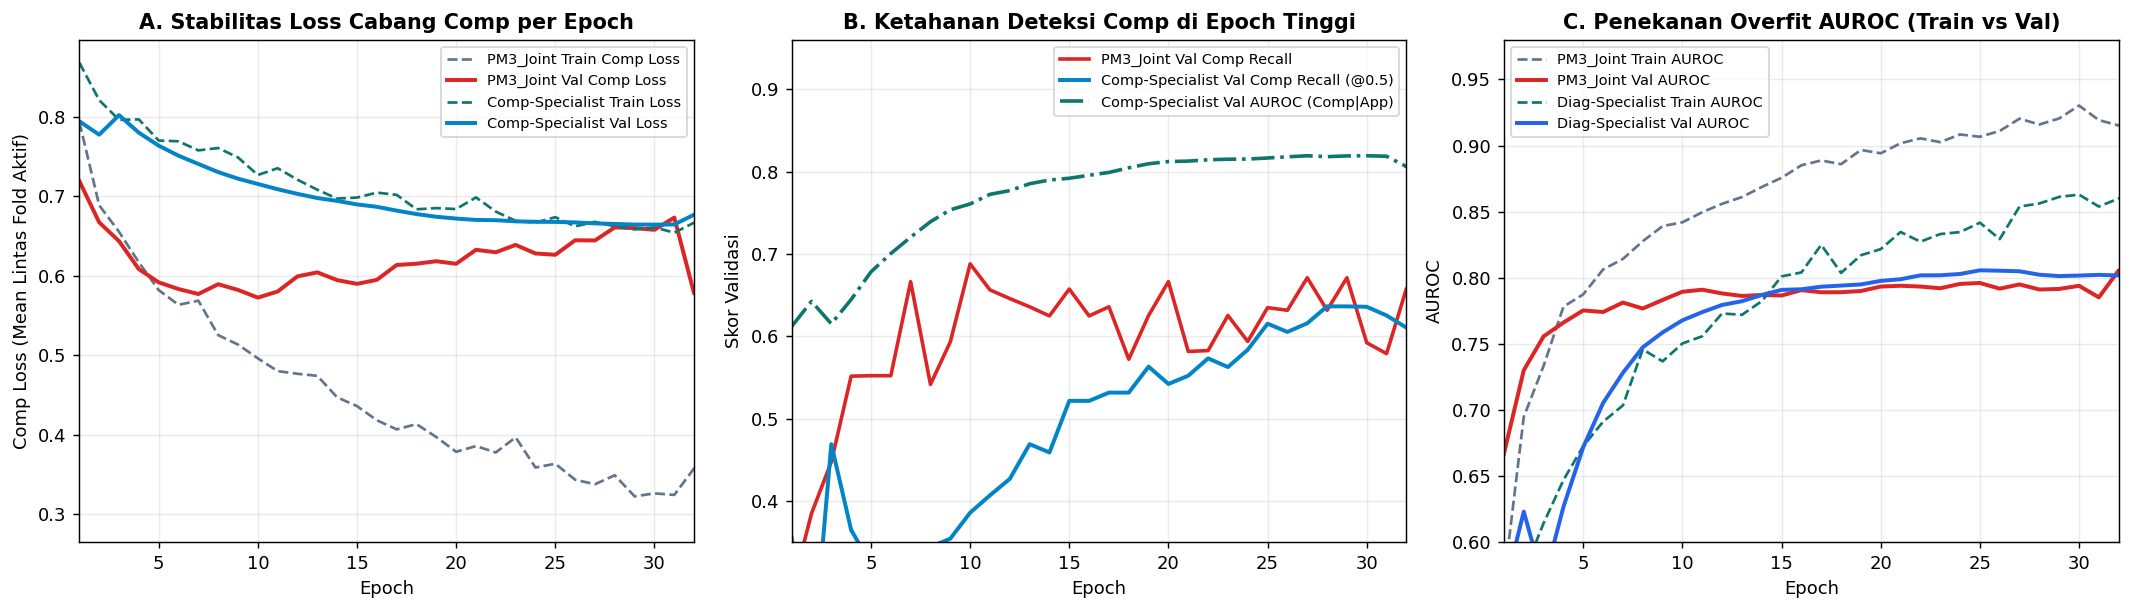

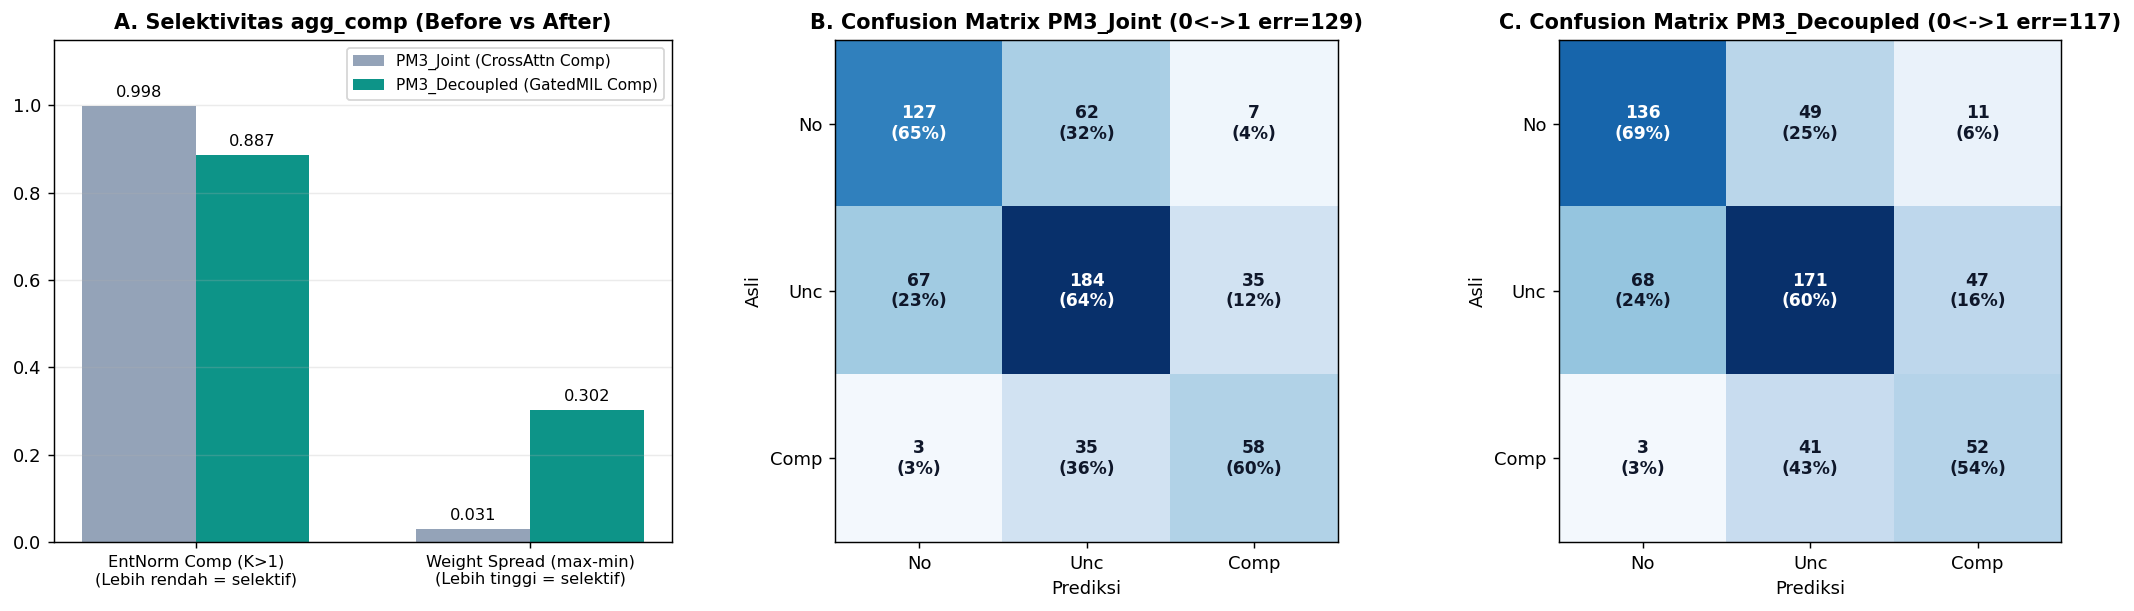

In [7]:
# ==============================================================================
# Cell 7: Visualisasi Audit 4 Kondisi
# ==============================================================================
plt.rcParams.update({"font.size": 10, "axes.titlesize": 11.5, "axes.titleweight": "bold"})

# Figure 1: Overfitting Gap & High-Epoch Comp Stability
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

# Panel A: Loss Gap & AUROC Gap comparison
ax = axes[0]
j_tr_l = j_hist.groupby("epoch")["train_loss_comp"].mean()
j_va_l = j_hist.groupby("epoch")["val_loss_comp"].mean()
d_tr_l = comp_hist.groupby("epoch")["train_loss_main"].mean()
d_va_l = comp_hist.groupby("epoch")["val_loss_main"].mean()
ax.plot(j_tr_l.index, j_tr_l.values, "--", color="#64748B", label="PM3_Joint Train Comp Loss")
ax.plot(j_va_l.index, j_va_l.values, "-", lw=2.2, color="#DC2626", label="PM3_Joint Val Comp Loss")
ax.plot(d_tr_l.index, d_tr_l.values, "--", color="#0F766E", label="Comp-Specialist Train Loss")
ax.plot(d_va_l.index, d_va_l.values, "-", lw=2.2, color="#0284C7", label="Comp-Specialist Val Loss")
ax.set_title("A. Stabilitas Loss Cabang Comp per Epoch")
ax.set_xlabel("Epoch")
ax.set_ylabel("Comp Loss (Mean Lintas Fold Aktif)")
ax.set_xlim(1, 32)
ax.grid(alpha=0.25)
ax.legend(fontsize=8)

# Panel B: High-epoch Comp AUROC & Recall stability
ax = axes[1]
j_rec = j_hist.groupby("epoch")["val_complication_recall"].mean()
d_rec = comp_hist.groupby("epoch")["val_recall_05"].mean()
d_auc = comp_hist.groupby("epoch")["val_auroc"].mean()
ax.plot(j_rec.index, j_rec.values, "-", lw=2.0, color="#DC2626", label="PM3_Joint Val Comp Recall")
ax.plot(d_rec.index, d_rec.values, "-", lw=2.2, color="#0284C7", label="Comp-Specialist Val Comp Recall (@0.5)")
ax.plot(d_auc.index, d_auc.values, "-.", lw=2.0, color="#0F766E", label="Comp-Specialist Val AUROC (Comp|App)")
ax.set_title("B. Ketahanan Deteksi Comp di Epoch Tinggi")
ax.set_xlabel("Epoch")
ax.set_ylabel("Skor Validasi")
ax.set_xlim(1, 32)
ax.set_ylim(0.35, 0.96)
ax.grid(alpha=0.25)
ax.legend(fontsize=8)

# Panel C: Diag-Specialist Train vs Val AUROC Gap vs PM3_Joint
ax = axes[2]
j_tr_a = j_hist.groupby("epoch")["train_primary_auroc"].mean()
j_va_a = j_hist.groupby("epoch")["val_primary_auroc"].mean()
da_tr_a = diag_hist.groupby("epoch")["train_auroc"].mean()
da_va_a = diag_hist.groupby("epoch")["val_auroc"].mean()
ax.plot(j_tr_a.index, j_tr_a.values, "--", color="#64748B", label="PM3_Joint Train AUROC")
ax.plot(j_va_a.index, j_va_a.values, "-", lw=2.2, color="#DC2626", label="PM3_Joint Val AUROC")
ax.plot(da_tr_a.index, da_tr_a.values, "--", color="#0F766E", label="Diag-Specialist Train AUROC")
ax.plot(da_va_a.index, da_va_a.values, "-", lw=2.2, color="#2563EB", label="Diag-Specialist Val AUROC")
ax.set_title("C. Penekanan Overfit AUROC (Train vs Val)")
ax.set_xlabel("Epoch")
ax.set_ylabel("AUROC")
ax.set_xlim(1, 32)
ax.set_ylim(0.60, 0.98)
ax.grid(alpha=0.25)
ax.legend(fontsize=8)

plt.tight_layout()
fig1_p = OUT_DIR / "08_overfit_and_epoch_stability.png"
fig.savefig(fig1_p, dpi=180, bbox_inches="tight")
plt.show()

# Figure 2: Selective Gated MIL Comp vs Uniform + No vs Unc Confusion Matrix
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

# Panel A: EntNorm & Spread agg_comp
ax = axes[0]
cats = ["EntNorm Comp (K>1)\n(Lebih rendah = selektif)", "Weight Spread (max-min)\n(Lebih tinggi = selektif)"]
v_before = [float(joint_mil_best["ent_norm_comp"]), float(joint_mil_best["spread_comp"])]
v_after = [float(comp_fold_df["entropy_norm_mv"].mean()), float(comp_fold_df["attn_spread_mv"].mean())]
x = np.arange(len(cats))
w = 0.34
b1 = ax.bar(x - w / 2, v_before, w, color="#94A3B8", label="PM3_Joint (CrossAttn Comp)")
b2 = ax.bar(x + w / 2, v_after, w, color="#0D9488", label="PM3_Decoupled (GatedMIL Comp)")
for bar in list(b1) + list(b2):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.02, f"{bar.get_height():.3f}", ha="center", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(cats, fontsize=9)
ax.set_ylim(0, 1.15)
ax.set_title("A. Selektivitas agg_comp (Before vs After)")
ax.grid(axis="y", alpha=0.25)
ax.legend(fontsize=8.5)

# Panel B: Confusion Matrix PM3_Joint vs PM3_Decoupled
for idx_cm, (ttl, df_m) in enumerate([
    ("B. Confusion Matrix PM3_Joint", pm3_joint_oof),
    ("C. Confusion Matrix PM3_Decoupled", dec_oof),
]):
    ax = axes[idx_cm + 1]
    cm = confusion_matrix(df_m["label"], df_m["pred_calibrated"], labels=[0, 1, 2])
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=max(100, cm.max()))
    for r in range(3):
        for c in range(3):
            col = "white" if cm[r, c] > cm.max() * 0.55 else "#0F172A"
            ax.text(c, r, f"{cm[r, c]}\n({cm[r, c] / cm[r].sum():.0%})", ha="center", va="center", color=col, fontsize=9.5, fontweight="bold")
    ax.set_xticks([0, 1, 2])
    ax.set_yticks([0, 1, 2])
    ax.set_xticklabels(["No", "Unc", "Comp"])
    ax.set_yticklabels(["No", "Unc", "Comp"])
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Asli")
    ax.set_title(f"{ttl} (0<->1 err={cm[0,1]+cm[1,0]})")

plt.tight_layout()
fig2_p = OUT_DIR / "08_gated_mil_comp_and_confusion.png"
fig.savefig(fig2_p, dpi=180, bbox_inches="tight")
plt.show()
print("Saved plots:", fig1_p, fig2_p)
